# 11주차 강의자 시연 완성본 — 환경·기후 데이터의 가공 및 분석
인공지능과 데이터 활용 · 2026-2학기 · 120분

**오늘의 질문:** 기상청이 공개한 관측 자료로 *내일 평균기온*을 예측하면, 단순한 규칙과 AI(머신러닝) 중 무엇이 더 정확할까? AI는 정말 단순 규칙보다 나을까?

| 단계 | 내용 | 결과물 |
|---|---|---|
| 0~2 | 준비, 기상청 ASOS 시간자료 불러오기·살펴보기 | 43,823행 × 8열 |
| 3~4 | **가공**: 시간자료 → 일자료(평균·최고·최저기온, 일교차, 일강수량), 품질 점검 | `week11_daily.csv` |
| 5~6 | **분석**: 변동성(이동평균)·계절성(월별 기후 그래프) | 그림 3장 |
| ✍️ | 기록 1 (Q1~Q4) | 답변 |
| 7 | 예측 문제 만들기: 입력(지난 7일)과 정답(내일) | 학습 1,446 / 평가 365행 |
| 8 | 단순 추세 예측 3가지 | 예측값 |
| 9 | AI 예측 2가지(선형회귀, 랜덤 포레스트) | 예측값 |
| 10 | 오차 비교(MAE·RMSE)와 그래프 | 표 1개, 그림 4장 |
| ✍️ | 기록 2 (Q5~Q8), 제출 ZIP | ZIP |

**사용 방법:** `파일 → Drive에 사본 저장` 후 **위에서부터 한 셀씩 ▶ 실행**합니다(또는 `런타임 → 모두 실행`). 런타임을 다시 시작했다면 0단계부터 다시 실행합니다. GPU는 필요 없습니다.

> 🧑‍🏫 이 노트북은 모든 셀을 실행해 둔 **강의자 시연 완성본**입니다. 기록 셀에 예시 답변이 들어 있습니다. 학생 워크북과 분리된 파일이므로 여기서 실행해도 학생 노트북에는 영향이 없습니다.


## 0단계. 실습 준비 (3분)
그래프에 한글이 보이도록 한글 폰트 패키지를 설치하고, 사용할 도구를 불러옵니다.

| 도구 | 하는 일 |
|---|---|
| `pandas` | 표(DataFrame) 데이터 읽기·가공 |
| `numpy` | 수치 계산(평균, 직선 맞추기 등) |
| `matplotlib` + `koreanize_matplotlib` | 그래프 그리기 + 한글 폰트 |
| `scikit-learn` | 머신러닝 모델(선형회귀, 랜덤 포레스트)과 오차 계산 |

결과 파일은 `week11_outputs` 폴더에 저장됩니다.

✅ **확인:** `준비 완료`가 출력되면 다음 단계로 갑니다. (설치 메시지가 몇 줄 나올 수 있습니다.)

In [1]:
import subprocess, sys
try:
    import koreanize_matplotlib            # 그래프 한글 폰트
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'koreanize-matplotlib'], check=False)
    try:
        import koreanize_matplotlib
    except ImportError:
        print('⚠️ 한글 폰트 설치 실패: 그래프 한글이 네모로 보일 수 있지만 실습은 계속할 수 있습니다.')

from pathlib import Path
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False   # 음수 기호가 깨지지 않게
OUT = Path('week11_outputs')
OUT.mkdir(exist_ok=True)
print('준비 완료 · pandas', pd.__version__)

준비 완료 · pandas 3.0.5


## 1단계. 기상청 ASOS 시간자료 불러오기 (4분)
**ASOS(종관기상관측)** 는 기상청이 전국 약 100개 관측소에서 기온·강수·바람·습도 등을 자동으로 재는 지상 관측망입니다. 오늘은 **대구 관측소(지점번호 143)** 의 2021-01-01 00시 ~ 2025-12-31 23시 **1시간 간격** 관측값을 씁니다.

- 원본: [기상청 기상자료개방포털 → 데이터 → 기상관측 → 지상 → 종관기상관측(ASOS) → 시간자료](https://data.kma.go.kr/data/grnd/selectAsosRltmList.do?pgmNo=36)에서 연도별로 받은 CSV 5개
- 실습 파일: 5개를 이어 붙이고 글자 인코딩만 UTF-8로 바꾼 `daegu_asos_hourly_2021_2025.csv` (값은 바꾸지 않음)
- 파일 위치: [Google Drive 01_실습데이터](https://drive.google.com/drive/folders/1lYrWd8lkkkVfeo3Ry83Fd_t72O4Lp9Ke)

| 코드 | 하는 일 |
|---|---|
| `gdown.download(id=..., output=...)` | Drive 파일을 Colab으로 내려받기 |
| `pd.read_csv(경로)` | CSV를 표(DataFrame)로 읽기 |

Drive가 일시적으로 안 되면 수업 GitHub 사본으로 자동 전환되고, 그래도 안 되면 업로드 창이 열립니다(Drive 폴더에서 CSV를 받아 올리기).

✅ **확인:** `✔ [Google Drive]` 와 `(43823, 8)` 이 출력되어야 합니다.

In [2]:
DRIVE_FOLDER = 'https://drive.google.com/drive/folders/1lYrWd8lkkkVfeo3Ry83Fd_t72O4Lp9Ke'   # 01_실습데이터
DRIVE_ID = '1-Gq7nccoGFw2rigpu010WwQVXDOlPO21'
NAME = 'daegu_asos_hourly_2021_2025.csv'
EXPECTED = (43823, 8)
BACKUP = 'https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week11/data/' + NAME          # Drive 접속 실패 시에만 쓰는 백업
DATA_DIR = Path('week11_data')
DATA_DIR.mkdir(exist_ok=True)
path = DATA_DIR / NAME

def read_ok(src):
    try:
        df = pd.read_csv(src)
        return df if df.shape == EXPECTED else None
    except Exception:
        return None

hourly = None
try:                                   # ① Google Drive
    import gdown
    gdown.download(id=DRIVE_ID, output=str(path), quiet=True)
    hourly = read_ok(path)
    if hourly is not None:
        print('✔ [Google Drive]', NAME, hourly.shape)
except Exception as e:
    print('  Drive 내려받기 실패:', type(e).__name__)
if hourly is None:                     # ② 백업: 수업 GitHub
    hourly = read_ok(BACKUP)
    if hourly is not None:
        print('✔ [GitHub 백업]', NAME, hourly.shape)
if hourly is None:                     # ③ 직접 업로드
    from google.colab import files
    print(NAME, '파일을 업로드하세요. (Drive 폴더:', DRIVE_FOLDER, ')')
    up = files.upload()
    hourly = pd.read_csv(list(up.keys())[0])

assert hourly.shape == EXPECTED, '행·열 수가 다릅니다. 파일을 다시 받으세요.'
print(hourly.shape)

  Drive 내려받기 실패: ProxyError


✔ [GitHub 백업] daegu_asos_hourly_2021_2025.csv (43823, 8)
(43823, 8)


## 2단계. 원자료 살펴보기 (5분)
가공하기 전에 **한 행이 무엇을 뜻하는지**, **비어 있는 칸이 어디에 있는지** 먼저 확인합니다.

| 열 | 단위 | 뜻 |
|---|---|---|
| `지점`, `지점명` | – | 관측소 번호와 이름 (143, 대구) |
| `일시` | 시각 | 관측 시각. 한 행 = **1시간** |
| `기온(°C)` | °C | 그 시각의 기온 |
| `강수량(mm)` | mm | 그 1시간 동안 내린 비·눈의 양. **빈칸은 강수가 기록되지 않은 시간** |
| `풍속(m/s)`, `풍향(16방위)` | m/s, ° | 바람 세기, 불어오는 방향(0/360=북, 90=동, 180=남, 270=서) |
| `습도(%)` | % | 상대습도 |

`isna().sum()` 은 열마다 빈칸이 몇 개인지 셉니다.

✅ **확인:** 강수량 빈칸 **40,060개**(비 안 온 시간), 습도 빈칸 **4개**, 기온 빈칸 0개. 5년 × 365일(+윤년 1일) × 24시간 = 43,824시간인데 행은 **43,823**개 → **1시간이 통째로 빠져 있습니다**(4단계에서 찾습니다).

In [3]:
display(hourly.head(3))
print('빈칸 수')
print(hourly.isna().sum())
print('기대 시간 수 =', (365 * 5 + 1) * 24, '/ 실제 행 수 =', len(hourly))

,지점,지점명,일시,기온(°C),강수량(mm),풍속(m/s),풍향(16방위),습도(%)
0,143,대구,2021-01-01 00:00,-4.1,NaN,4.4,290,63.0
1,143,대구,2021-01-01 01:00,-4.5,NaN,2.6,320,61.0
2,143,대구,2021-01-01 02:00,-5.0,NaN,1.6,340,64.0


빈칸 수
지점              0
지점명             0
일시              0
기온(°C)          0
강수량(mm)     40060
풍속(m/s)         0
풍향(16방위)        0
습도(%)           4
dtype: int64
기대 시간 수 = 43824 / 실제 행 수 = 43823


## 3단계. 가공① 시간자료 → 일자료 만들기 (10분)
예측은 **하루 단위**로 하므로, 24개의 시간 관측을 날짜별로 묶어 하루 값으로 요약합니다. 이것이 오늘의 핵심 **데이터 가공**입니다.

![시간자료→일자료](https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week11/figures/c2_hourly_to_daily.png)

| 만들 열 | 계산 | 코드 |
|---|---|---|
| 평균기온 | 24개 기온의 평균 | `('기온(°C)', 'mean')` |
| 최고기온 / 최저기온 | 24개 중 최댓값 / 최솟값 | `'max'` / `'min'` |
| 일강수량 | 24시간 강수량의 **합** (빈칸은 0으로 보고 더함) | `'sum'` |
| 평균습도, 평균풍속 | 평균 | `'mean'` |
| 관측수 | 기온이 있는 시간 수(정상이면 24) | `'count'` |
| 일교차 | 최고기온 − 최저기온 | 열끼리 빼기 |

- `pd.to_datetime` : 글자 `'2025-01-01 13:00'` → 날짜·시각 자료형
- `.dt.normalize()` : 시각을 버리고 날짜(00:00)만 남김 → 같은 날짜끼리 묶을 열
- `groupby('날짜').agg(...)` : 날짜별로 묶어 위 표의 계산을 한 번에 수행

> 참고: 기상청이 따로 제공하는 *공식 일자료*의 최고·최저기온은 1분 단위로 잰 값이라, 정시 관측 24개로 만든 오늘의 값과 조금 다를 수 있습니다.

✅ **확인:** `(1826, 8)` — 2021~2025년 날짜 1,826일, 열 8개.

In [4]:
hourly['일시'] = pd.to_datetime(hourly['일시'])
hourly['날짜'] = hourly['일시'].dt.normalize()
hourly['강수량(mm)'] = hourly['강수량(mm)'].fillna(0)      # 빈칸 = 강수 없음 → 0

daily = hourly.groupby('날짜').agg(
    평균기온=('기온(°C)', 'mean'),
    최고기온=('기온(°C)', 'max'),
    최저기온=('기온(°C)', 'min'),
    일강수량=('강수량(mm)', 'sum'),
    평균습도=('습도(%)', 'mean'),
    평균풍속=('풍속(m/s)', 'mean'),
    관측수=('기온(°C)', 'count'),
)
daily['일교차'] = daily['최고기온'] - daily['최저기온']
print(daily.shape)
display(daily.head().round(1))

(1826, 8)


,평균기온,최고기온,최저기온,일강수량,평균습도,평균풍속,관측수,일교차
날짜,,,,,,,,
2021-01-01,-2.0,2.1,-5.6,0.0,64.4,2.0,24,7.7
2021-01-02,-1.1,1.7,-3.6,0.0,55.5,3.2,24,5.3
2021-01-03,-1.3,2.1,-4.0,0.0,41.5,4.0,24,6.1
2021-01-04,-0.3,5.5,-5.7,0.0,51.9,1.5,24,11.2
2021-01-05,-0.7,2.4,-4.5,0.0,48.1,3.2,24,6.9


## 4단계. 가공② 품질 점검과 저장 (5분)
가공한 표를 그대로 믿지 않고 **검사**합니다.

1. **빠진 날짜가 없는가?** `asfreq('D')` 는 하루 간격으로 달력을 다시 맞춥니다. 빠진 날이 있으면 행이 늘어나고 빈칸이 생깁니다.
2. **24시간을 다 채운 날인가?** 관측수가 24보다 적은 날은 평균이 치우칠 수 있습니다. 예) 가장 더운 오후 1시간이 빠지면 평균기온이 실제보다 낮아집니다. 그래서 그날 기온 값을 **결측(NaN)** 으로 바꿉니다. 0°C로 채우면 안 됩니다 — 여름에 0°C는 거짓 값입니다.
3. 결과를 `week11_daily.csv` 로 저장합니다(가공 결과물).

✅ **확인:** `24시간 미만 관측일: 2022-08-06 (23시간)` 1건, 저장 후 `(1826, 8)`.

In [5]:
daily = daily.asfreq('D')
assert len(daily) == 1826, '날짜 수가 1826이 아닙니다.'

short = daily[daily['관측수'] < 24]
for day, n in short['관측수'].items():
    print(f'24시간 미만 관측일: {day.date()} ({int(n)}시간)')

temp_cols = ['평균기온', '최고기온', '최저기온', '일교차']
daily.loc[daily['관측수'] < 24, temp_cols] = np.nan     # 불완전한 날 → 결측
daily.round(3).to_csv(OUT / 'week11_daily.csv', encoding='utf-8-sig')
print('저장:', OUT / 'week11_daily.csv', daily.shape)
display(daily.loc['2022-08-04':'2022-08-08'].round(1))

24시간 미만 관측일: 2022-08-06 (23시간)
저장: week11_outputs/week11_daily.csv (1826, 8)


,평균기온,최고기온,최저기온,일강수량,평균습도,평균풍속,관측수,일교차
날짜,,,,,,,,
2022-08-04,30.6,34.7,27.4,0.0,76.4,2.4,24,7.3
2022-08-05,30.8,34.5,26.7,0.0,74.3,2.0,24,7.8
2022-08-06,NaN,NaN,NaN,0.0,73.7,1.7,23,NaN
2022-08-07,31.7,36.8,28.0,0.0,71.4,1.9,24,8.8
2022-08-08,30.6,34.2,27.4,0.0,69.6,2.1,24,6.8


## 5단계. 분석① 변동성 — 하루하루 얼마나 오르내리나 (7분)
**이동평균**은 최근 며칠의 값을 평균해 짧은 흔들림을 걸러 내는 방법입니다. `rolling(7).mean()` 은 *그날을 포함한 최근 7일 평균*입니다.

그림 읽는 법
- 회색 띠: 그날의 최저~최고기온(일교차)
- 연한 선: 일평균기온 / 진한 선: 7일 이동평균
- 이동평균은 실제 변화보다 **며칠 늦게** 따라갑니다(지난 값만 쓰기 때문).

✅ **확인:** 2025년 그래프와 `01_2025_daily_temp.png` 저장. 평균 일교차 **9.8°C**, 가장 더운 날 **2025-07-07 31.8°C**, 가장 추운 날 **2025-01-10 −5.9°C**.

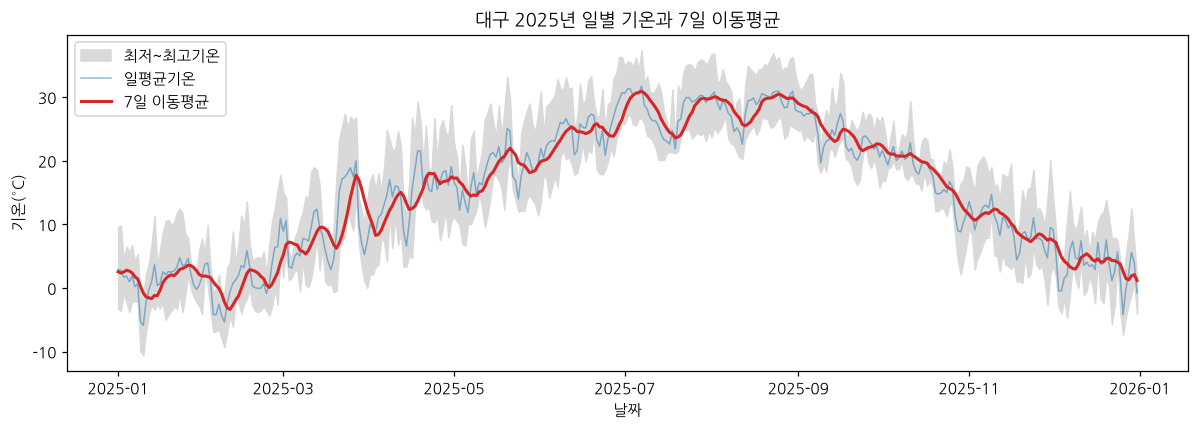

2025년 평균 일교차: 9.8°C
2025년 가장 더운 날: 2025-07-07 31.8°C
2025년 가장 추운 날: 2025-01-10 -5.9°C


In [6]:
temp = daily['평균기온']
ma7 = temp.rolling(7).mean()
y25 = daily.loc['2025']

fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(y25.index, y25['최저기온'], y25['최고기온'], color='0.85', label='최저~최고기온')
ax.plot(y25.index, y25['평균기온'], color='tab:blue', alpha=0.5, lw=1, label='일평균기온')
ax.plot(ma7.loc['2025'].index, ma7.loc['2025'], color='tab:red', lw=2, label='7일 이동평균')
ax.set(title='대구 2025년 일별 기온과 7일 이동평균', xlabel='날짜', ylabel='기온(°C)')
ax.legend(loc='upper left')
fig.tight_layout(); fig.savefig(OUT / '01_2025_daily_temp.png', dpi=150); plt.show()

print('2025년 평균 일교차: %.1f°C' % y25['일교차'].mean())
print('2025년 가장 더운 날:', y25['평균기온'].idxmax().date(), '%.1f°C' % y25['평균기온'].max())
print('2025년 가장 추운 날:', y25['평균기온'].idxmin().date(), '%.1f°C' % y25['평균기온'].min())

## 6단계. 분석② 계절성 — 해마다 반복되는 패턴 (8분)
같은 달끼리 묶으면 해마다 반복되는 **계절성**이 보입니다.

- 그림 2 **연도별 월평균기온**: 5개 선이 거의 겹치면 계절 패턴이 해마다 비슷하다는 뜻입니다.
- 그림 3 **기후 그래프**(월평균기온 선 + 월강수량 막대): 대구는 7~8월에 덥고 비가 많습니다.
- 표 **연도별 요약**: 연평균기온과 연강수량.

> ⚠️ 5년치로는 *기후 변화(장기 추세)* 를 판단할 수 없습니다. 기상청의 기후 *평년값*은 30년 평균을 씁니다. 오늘 자료로는 계절 패턴과 **하루 뒤 예측**까지만 다룹니다.

✅ **확인:** 그림 2장 저장. 월평균기온 1월 **1.2°C** → 8월 **27.6°C**, 월강수량 7월 **232 mm**·8월 198 mm가 가장 많음. 연평균기온 14.7~15.9°C, 연강수량은 2022년 581 mm ~ 2023년 1,322 mm로 해마다 차이가 큼.

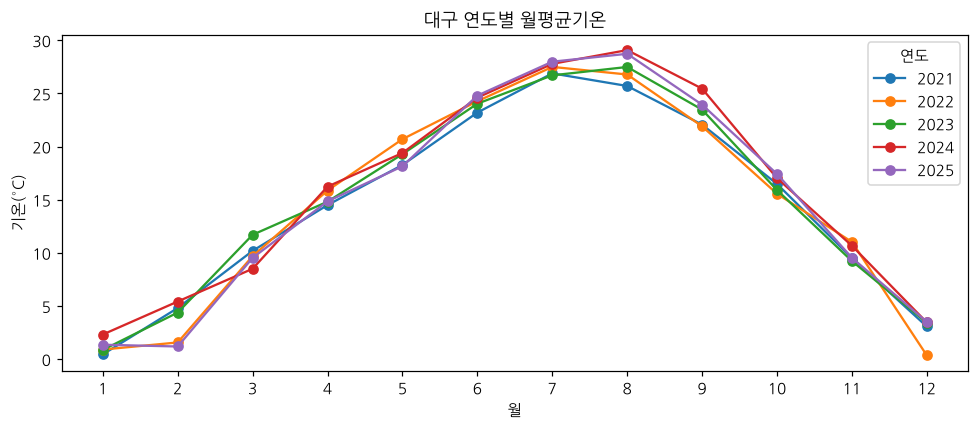

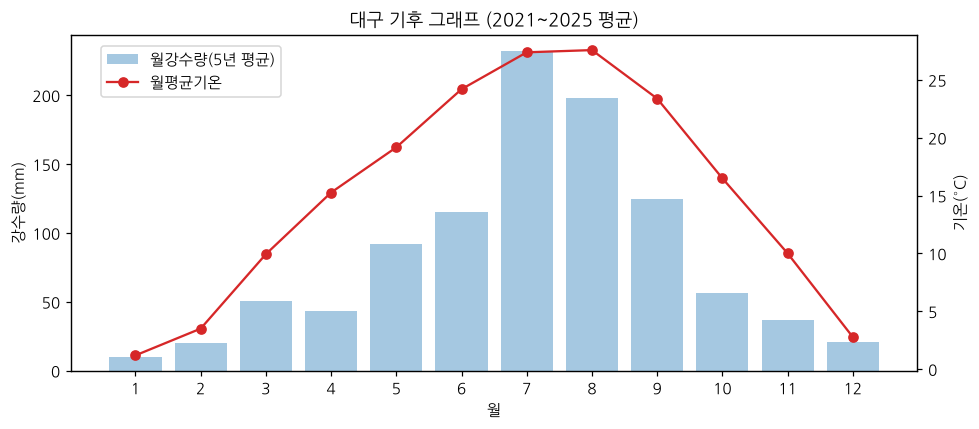

,연평균기온(°C),연강수량(mm),평균 일교차(°C)
날짜,,,
2021,14.7,910.0,9.7
2022,14.7,581.0,10.0
2023,15.2,1322.0,10.0
2024,15.9,1156.0,9.4
2025,15.2,1029.0,9.8


In [7]:
month_year = daily.groupby([daily.index.year, daily.index.month])['평균기온'].mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 4))
month_year.plot(ax=ax, marker='o')
ax.set(title='대구 연도별 월평균기온', xlabel='월', ylabel='기온(°C)', xticks=range(1, 13))
ax.legend(title='연도')
fig.tight_layout(); fig.savefig(OUT / '02_monthly_by_year.png', dpi=150); plt.show()

clim = pd.DataFrame({
    '월평균기온': daily.groupby(daily.index.month)['평균기온'].mean(),
    '월강수량': daily.groupby([daily.index.year, daily.index.month])['일강수량'].sum().groupby(level=1).mean(),
})
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(clim.index, clim['월강수량'], color='tab:blue', alpha=0.4, label='월강수량(5년 평균)')
ax1.set(xlabel='월', ylabel='강수량(mm)', xticks=range(1, 13))
ax2 = ax1.twinx()
ax2.plot(clim.index, clim['월평균기온'], color='tab:red', marker='o', label='월평균기온')
ax2.set_ylabel('기온(°C)')
ax1.set_title('대구 기후 그래프 (2021~2025 평균)')
fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.9))
fig.tight_layout(); fig.savefig(OUT / '03_climate_graph.png', dpi=150); plt.show()

yearly = pd.DataFrame({
    '연평균기온(°C)': daily.groupby(daily.index.year)['평균기온'].mean().round(1),
    '연강수량(mm)': daily.groupby(daily.index.year)['일강수량'].sum().round(0),
    '평균 일교차(°C)': daily.groupby(daily.index.year)['일교차'].mean().round(1),
})
display(yearly)

## ✍️ 기록 1 — 가공·탐색 결과 (5분)
아래 셀의 따옴표 안 내용을 **본인이 확인한 결과로 바꿔** 적고 실행합니다. 숫자는 위 출력에서 그대로 옮깁니다.

In [8]:
answers1 = {
 "Q1_2025년_가장_더운_날과_가장_추운_날": "가장 더운 날 2025-07-07 31.8°C, 가장 추운 날 2025-01-10 -5.9°C",
 "Q2_불완전_관측일과_처리_이유": "2022-08-06은 23시간만 관측되었다. 빠진 시간에 따라 평균이 치우치므로 결측으로 두었다. 0°C로 채우면 실제와 전혀 다른 거짓 값이 된다.",
 "Q3_기후_그래프에서_찾은_계절_특징": "7~8월이 가장 덥고(월평균 27.4~27.6°C) 비도 가장 많다(7월 232 mm). 1월은 1.2°C로 가장 춥고 강수량도 10 mm로 가장 적다.",
 "Q4_5년_자료로_기후변화를_말하기_어려운_이유": "연강수량이 581~1,322 mm로 해마다 크게 달라지듯 자연 변동이 커서 5년 차이는 우연일 수 있고, 기후는 보통 30년 평균으로 판단하기 때문이다."
}
for k, v in answers1.items():
    print(k, '→', v)

Q1_2025년_가장_더운_날과_가장_추운_날 → 가장 더운 날 2025-07-07 31.8°C, 가장 추운 날 2025-01-10 -5.9°C
Q2_불완전_관측일과_처리_이유 → 2022-08-06은 23시간만 관측되었다. 빠진 시간에 따라 평균이 치우치므로 결측으로 두었다. 0°C로 채우면 실제와 전혀 다른 거짓 값이 된다.
Q3_기후_그래프에서_찾은_계절_특징 → 7~8월이 가장 덥고(월평균 27.4~27.6°C) 비도 가장 많다(7월 232 mm). 1월은 1.2°C로 가장 춥고 강수량도 10 mm로 가장 적다.
Q4_5년_자료로_기후변화를_말하기_어려운_이유 → 연강수량이 581~1,322 mm로 해마다 크게 달라지듯 자연 변동이 커서 5년 차이는 우연일 수 있고, 기후는 보통 30년 평균으로 판단하기 때문이다.


## 7단계. 예측 문제 만들기 — 입력(지난 7일)과 정답(그날) (10분)
예측하려는 날을 **D** 라고 하면, D의 전날 저녁까지 알 수 있는 정보만 입력으로 써야 합니다.

![지난 7일 → 그날](https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week11/figures/c3_lag_window.png)

| 열 | 뜻 | 만드는 코드 |
|---|---|---|
| `lag_1` … `lag_7` | 1일 전 … 7일 전 평균기온 | `temp.shift(i)` (값을 i칸 아래로 밀기) |
| `계절_sin`, `계절_cos` | 1년 중 위치(1월 1일과 12월 31일이 가깝도록 원 위의 좌표로 표현) | `np.sin`, `np.cos` |
| `정답` | D의 실제 평균기온 | `temp` |

**시간순 분할**: 2021~2024년으로 학습하고 2025년으로 평가합니다. 무작위로 섞어 나누면 *미래 날짜로 과거를 맞히는* 반칙이 섞이기 때문입니다.

![시간순 분할](https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week11/figures/c4_time_split.png)

`dropna()` 는 입력·정답 중 하나라도 비어 있는 행을 지웁니다. (처음 7일, 그리고 2022-08-06이 정답이거나 입력 7일 안에 들어간 8개 행)

✅ **확인:** `학습 1446 / 평가 365`. 표에서 2025-01-01 행의 `lag_1`(4.529)이 2024-12-31 행의 `정답`과 같아야 합니다.

In [9]:
frame = pd.DataFrame(index=temp.index)
lag_cols = [f'lag_{i}' for i in range(1, 8)]
for i, col in enumerate(lag_cols, start=1):
    frame[col] = temp.shift(i)                  # i일 전 기온

angle = 2 * np.pi * (frame.index.dayofyear - 1) / 365.25
frame['계절_sin'] = np.sin(angle)
frame['계절_cos'] = np.cos(angle)
frame['정답'] = temp

display(frame.loc['2024-12-30':'2025-01-02', ['lag_1', 'lag_2', 'lag_3', '정답']].round(3))

frame = frame.dropna()
train = frame.loc[:'2024-12-31']
test = frame.loc['2025-01-01':]
assert train.index.max() < test.index.min()    # 학습이 평가보다 과거인지 확인
print('학습', len(train), '/ 평가', len(test))

,lag_1,lag_2,lag_3,정답
날짜,,,,
2024-12-30,1.867,0.017,0.392,3.871
2024-12-31,3.871,1.867,0.017,4.529
2025-01-01,4.529,3.871,1.867,2.900
2025-01-02,2.900,4.529,3.871,2.771


학습 1446 / 평가 365


## 8단계. 단순 추세 예측 — 규칙 3가지 (10분)
학습 없이 **정해진 규칙**으로 예측합니다. AI와 비교할 *기준선(baseline)* 입니다.

| 방법 | 규칙 | 코드 |
|---|---|---|
| ① 어제 그대로(지속 예측) | 내일 = 오늘 | `lag_1` |
| ② 최근 7일 평균 | 내일 = 지난 7일 평균 | `test[lag_cols].mean(axis=1)` |
| ③ 최근 7일 직선 추세 | 지난 7일에 직선을 맞춰 하루 더 연장 | `np.polyfit(x, y, 1)` |

![단순 추세 3가지](https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week11/figures/c5_simple_rules.png)

`np.polyfit(x, y, 1)` 은 점들에 가장 잘 맞는 직선(1차식)의 *기울기*와 *절편*을 구합니다. x를 7일 전=−7, …, 1일 전=−1 로 두면 **x=0(오늘=D)에서의 값 = 절편** 이 바로 예측값입니다.

✅ **확인:** `pred` 표 첫 행(2025-01-01) — 실제 2.900, 어제 그대로 4.529, 7일 평균 2.502, 7일 직선추세 3.438. 🔧 셀 기본값(N=3) 결과는 `2.161°C`.

In [10]:
days = np.arange(-7, 0)                               # -7, -6, ..., -1
history = test[lag_cols[::-1]].to_numpy()             # 오래된 날 → 최근 날 순서
slope, intercept = np.polyfit(days, history.T, 1)     # 365일 각각에 직선 맞추기

pred = pd.DataFrame(index=test.index)
pred['실제'] = test['정답']
pred['어제 그대로'] = test['lag_1']
pred['7일 평균'] = test[lag_cols].mean(axis=1)
pred['7일 직선추세'] = intercept
display(pred.head(3).round(3))

,실제,어제 그대로,7일 평균,7일 직선추세
날짜,,,,
2025-01-01,2.900,4.529,2.502,3.438
2025-01-02,2.771,2.900,2.548,3.698
2025-01-03,1.683,2.771,2.335,4.559


### 🔧 바꿔 보기 (선택)
직선을 맞추는 기간 `N` 을 2~7 사이 숫자(예: 3, 5)로 바꿔 실행해 보세요. 입력이 지난 7일뿐이라 7까지만 가능합니다. 이 셀은 아래 단계에 영향을 주지 않습니다.

In [11]:
N = 3          # ← 2~7 사이 숫자로 바꿔 보기
x = np.arange(-N, 0)
_, b = np.polyfit(x, test[lag_cols[:N][::-1]].to_numpy().T, 1)
print(f'최근 {N}일 직선추세 MAE = {np.mean(np.abs(test["정답"] - b)):.3f}°C')

최근 3일 직선추세 MAE = 2.161°C


## 9단계. AI 예측 — 데이터에서 규칙을 학습 (10분)
AI(머신러닝)는 **2021~2024년의 (입력 → 정답) 1,446쌍** 에서 관계를 스스로 찾아, 처음 보는 2025년 날짜를 예측합니다.

| 모델 | 아이디어 |
|---|---|
| **선형회귀** | 정답 ≈ a₁·lag_1 + a₂·lag_2 + … + 계절항 + b. 각 입력의 *가중치*를 학습 |
| **랜덤 포레스트** | "어제가 3°C보다 낮은가?" 같은 질문을 이어 붙인 결정 트리 200개를 만들고 예측을 평균 |

![AI 학습과 예측](https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week11/figures/c6_ai_train_predict.png)

- `model.fit(X학습, y학습)` : 학습 / `model.predict(X평가)` : 예측
- `random_state=42` : 랜덤 요소를 고정해 누가 실행해도 같은 결과가 나오게 함
- **중요도 그림**: 랜덤 포레스트가 어떤 입력을 많이 썼는지 보여 줍니다.

✅ **확인:** 선형회귀 가중치 중 `lag_1` 이 **0.882** 로 가장 크고, 중요도 그림에서도 `lag_1`(어제 기온)이 압도적으로 큽니다.

선형회귀 가중치: {'lag_1': 0.882, 'lag_2': -0.263, 'lag_3': 0.059, 'lag_4': 0.06, 'lag_5': 0.01, 'lag_6': 0.007, 'lag_7': 0.011, '계절_sin': -0.715, '계절_cos': -2.91}


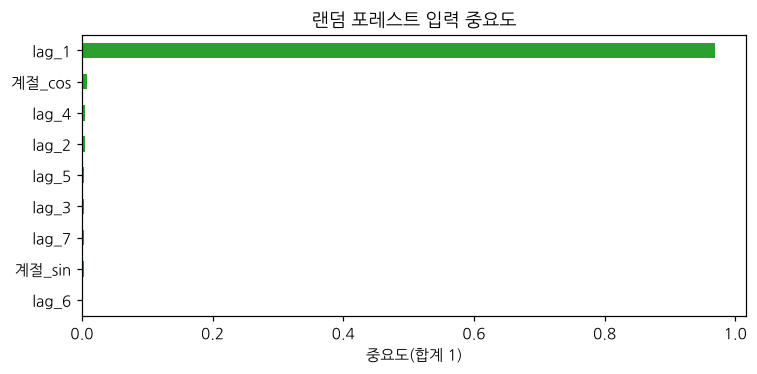

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

features = lag_cols + ['계절_sin', '계절_cos']
X_train, y_train = train[features], train['정답']
X_test = test[features]

lin = LinearRegression().fit(X_train, y_train)
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=1)
forest.fit(X_train, y_train)

pred['AI 선형회귀'] = lin.predict(X_test)
pred['AI 랜덤포레스트'] = forest.predict(X_test)
assert pred.notna().all().all()

print('선형회귀 가중치:', {f: round(float(w), 3) for f, w in zip(features, lin.coef_)})
imp = pd.Series(forest.feature_importances_, index=features).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
imp.plot.barh(ax=ax, color='tab:green')
ax.set(title='랜덤 포레스트 입력 중요도', xlabel='중요도(합계 1)')
fig.tight_layout(); fig.savefig(OUT / '04_rf_importance.png', dpi=150); plt.show()

## 10단계. 오차 비교 — 누가 더 정확한가? (15분)
같은 2025년 365일에 대해 다섯 방법의 오차를 잽니다.

| 지표 | 계산 | 해석 |
|---|---|---|
| **MAE** | \|실제 − 예측\| 의 평균 | "평균 몇 °C 빗나갔나" |
| **RMSE** | √(오차² 의 평균) | 크게 틀린 날에 벌점을 더 줌 (MAE ≤ RMSE) |

예) 이틀 오차가 0°C, 4°C → MAE = 2.0°C, RMSE = √((0+16)/2) ≈ 2.83°C

그림 4장: ⑤ 방법별 MAE 막대, ⑥ 1~2월 예측 비교 선그래프, ⑦ 월별 MAE, 그리고 오차가 큰 날 표.

✅ **확인 (기대 결과):**

| 방법 | MAE(°C) | RMSE(°C) |
|---|---|---|
| AI 선형회귀 | 1.566 | 2.049 |
| AI 랜덤포레스트 | 1.620 | 2.131 |
| 어제 그대로 | 1.633 | 2.184 |
| 7일 직선추세 | 2.389 | 3.127 |
| 7일 평균 | 2.500 | 3.177 |

AI 랜덤포레스트가 가장 크게 틀린 날은 **2025-03-28** (실제 9.97°C, 예측 18.00°C, 오차 8.03°C).

(scikit-learn 버전에 따라 랜덤 포레스트의 소수 셋째 자리는 조금 다를 수 있습니다.)

,MAE(°C),RMSE(°C)
AI 선형회귀,1.566,2.049
AI 랜덤포레스트,1.620,2.131
어제 그대로,1.633,2.184
7일 직선추세,2.389,3.127
7일 평균,2.500,3.177


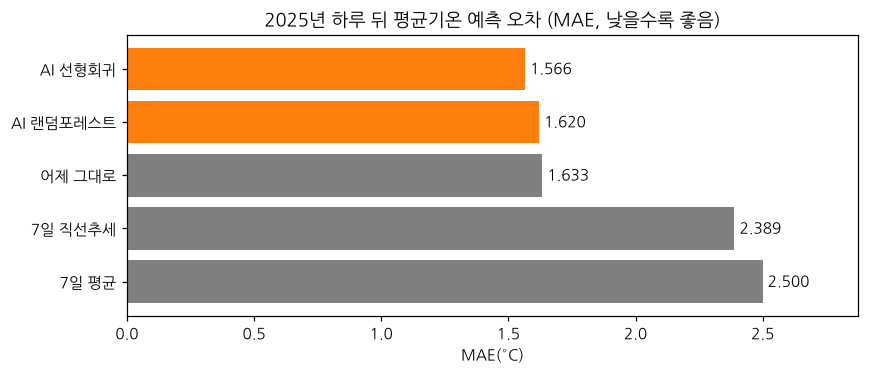

In [13]:
methods = ['어제 그대로', '7일 평균', '7일 직선추세', 'AI 선형회귀', 'AI 랜덤포레스트']
err = pred[methods].sub(pred['실제'], axis=0)          # 예측 - 실제
metrics = pd.DataFrame({
    'MAE(°C)': err.abs().mean(),
    'RMSE(°C)': np.sqrt((err ** 2).mean()),
}).sort_values('MAE(°C)')
display(metrics.round(3))

colors = ['tab:orange' if m.startswith('AI') else 'tab:gray' for m in metrics.index]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(metrics.index[::-1], metrics['MAE(°C)'][::-1], color=colors[::-1])
for y, v in enumerate(metrics['MAE(°C)'][::-1]):
    ax.text(v + 0.02, y, f'{v:.3f}', va='center')
ax.set(title='2025년 하루 뒤 평균기온 예측 오차 (MAE, 낮을수록 좋음)', xlabel='MAE(°C)')
ax.set_xlim(0, metrics['MAE(°C)'].max() * 1.15)
fig.tight_layout(); fig.savefig(OUT / '05_mae_bar.png', dpi=150); plt.show()

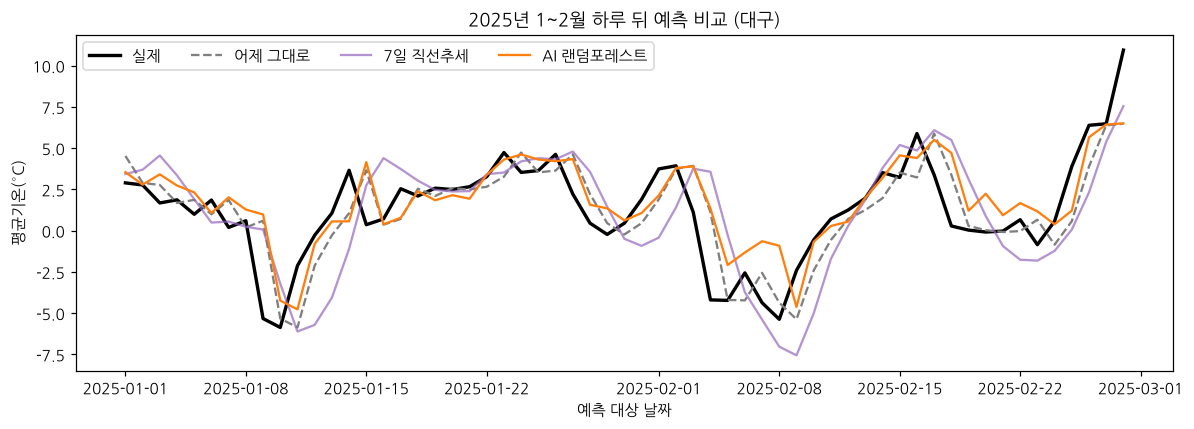

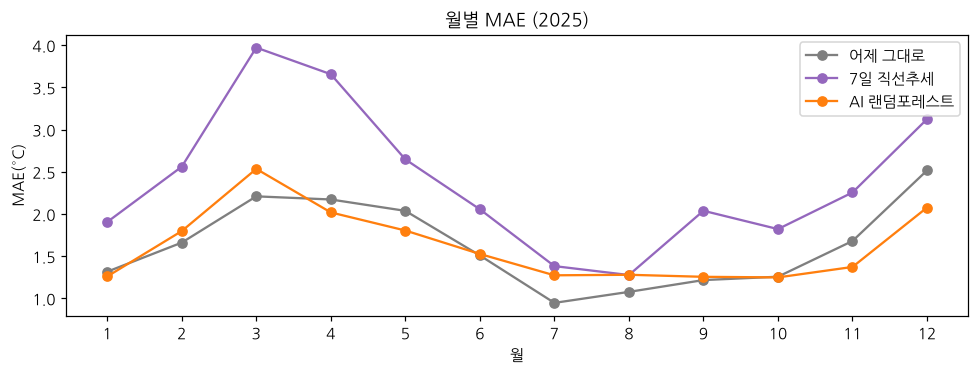

AI 랜덤포레스트가 가장 크게 틀린 5일


,실제,어제 그대로,AI 랜덤포레스트,RF_절대오차
날짜,,,,
2025-03-28,9.97,19.99,18.00,8.03
2025-03-21,15.15,8.47,8.58,6.57
2025-01-09,-5.32,0.60,0.99,6.31
2025-09-09,19.64,24.14,25.79,6.15
2025-03-03,3.37,10.57,9.16,5.79


In [14]:
win = pred.loc['2025-01-01':'2025-02-28']
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(win.index, win['실제'], color='black', lw=2.2, label='실제')
ax.plot(win.index, win['어제 그대로'], color='tab:gray', ls='--', label='어제 그대로')
ax.plot(win.index, win['7일 직선추세'], color='tab:purple', alpha=0.7, label='7일 직선추세')
ax.plot(win.index, win['AI 랜덤포레스트'], color='tab:orange', label='AI 랜덤포레스트')
ax.set(title='2025년 1~2월 하루 뒤 예측 비교 (대구)', xlabel='예측 대상 날짜', ylabel='평균기온(°C)')
ax.legend(ncol=4, loc='upper left')
fig.tight_layout(); fig.savefig(OUT / '06_janfeb_lines.png', dpi=150); plt.show()

monthly_mae = err.abs().groupby(err.index.month).mean()[['어제 그대로', '7일 직선추세', 'AI 랜덤포레스트']]
fig, ax = plt.subplots(figsize=(9, 3.5))
monthly_mae.plot(ax=ax, marker='o', color=['tab:gray', 'tab:purple', 'tab:orange'])
ax.set(title='월별 MAE (2025)', xlabel='월', ylabel='MAE(°C)', xticks=range(1, 13))
fig.tight_layout(); fig.savefig(OUT / '07_monthly_mae.png', dpi=150); plt.show()

big = pred.assign(RF_절대오차=(pred['AI 랜덤포레스트'] - pred['실제']).abs())
big = big.sort_values('RF_절대오차', ascending=False).head(5)
print('AI 랜덤포레스트가 가장 크게 틀린 5일')
display(big[['실제', '어제 그대로', 'AI 랜덤포레스트', 'RF_절대오차']].round(2))

### 결과 읽기 (강의 포인트)
1. **AI가 '7일 직선추세'보다는 확실히 낫다** (MAE 약 0.77°C 차이). 직선 연장은 추위가 풀리기 시작하는 날에도 계속 내려가는 식으로 *과하게 따라가기* 때문입니다(그림 6의 보라색 선).
2. **하지만 '어제 그대로'와 AI 랜덤포레스트의 차이는 0.01°C 수준**입니다. 중요도 그림처럼 모델이 사실상 *어제 기온* 에 기대고 있어, 그림 6에서 AI 선이 실제 선을 **하루 늦게** 따라가는 모습이 보입니다.
3. 가장 단순한 AI(선형회귀)가 더 복잡한 랜덤 포레스트보다 약간 낫습니다. **복잡한 모델 = 더 정확** 은 아닙니다.
4. 크게 틀린 날은 **하루 사이에 기온이 급변한 날**입니다. 예) 2025-03-28은 전날 20.0°C에서 10.0°C로 하루 만에 10°C 떨어졌습니다. 기온만 보는 모델은 찬 공기가 몰려오는 것을 알 수 없습니다. 기상청의 실제 단기예보는 전 지구 관측과 대기의 물리 법칙을 계산하는 *수치예보모델* 을 쓰고, 최근에는 AI 예보 모델도 함께 연구·활용합니다.
5. 그림 7(월별 MAE)을 보면 **봄(3~4월)과 12월은 오차가 크고 여름(7~8월)은 작습니다.** 계절이 바뀌는 시기에 기온이 크게 오르내리기 때문입니다. 3월, 7~8월에는 랜덤 포레스트가 '어제 그대로'보다 오히려 오차가 큽니다.

👉 **AI의 성능은 항상 '적절한 기준선'과 비교해서 말해야 합니다.**

## ✍️ 기록 2 — 예측 결과 해석 (8분)
10단계 표·그림을 근거로 작성합니다. 숫자는 출력에서 그대로 옮깁니다.

In [15]:
answers2 = {
 "Q5_MAE_순위와_값": "AI 선형회귀 1.566 < AI 랜덤포레스트 1.620 < 어제 그대로 1.633 < 7일 직선추세 2.389 < 7일 평균 2.500 (°C)",
 "Q6_AI_랜덤포레스트_vs_어제그대로_차이": "약 0.01°C로 거의 같다. 랜덤 포레스트가 어제 기온에 크게 의존해 '어제 그대로'와 비슷하게 예측하기 때문이다.",
 "Q7_가장_크게_틀린_날_하나와_이유": "2025-03-28: 실제 9.97°C, 랜덤 포레스트 18.00°C(오차 8.03°C). 전날 19.99°C에서 하루 만에 10°C 떨어졌는데, 모델은 전날 기온 근처를 예측했다. 지난 기온만으로는 찬 공기가 들어오는 것을 미리 알 수 없다.",
 "Q8_예측을_더_잘하려면_추가할_데이터": "서쪽(상류) 관측소 기온과 기압 변화, 풍향을 넣는다. 찬 공기가 몰려오는 신호가 하루 먼저 나타나기 때문이다."
}
for k, v in answers2.items():
    print(k, '→', v)

Q5_MAE_순위와_값 → AI 선형회귀 1.566 < AI 랜덤포레스트 1.620 < 어제 그대로 1.633 < 7일 직선추세 2.389 < 7일 평균 2.500 (°C)
Q6_AI_랜덤포레스트_vs_어제그대로_차이 → 약 0.01°C로 거의 같다. 랜덤 포레스트가 어제 기온에 크게 의존해 '어제 그대로'와 비슷하게 예측하기 때문이다.
Q7_가장_크게_틀린_날_하나와_이유 → 2025-03-28: 실제 9.97°C, 랜덤 포레스트 18.00°C(오차 8.03°C). 전날 19.99°C에서 하루 만에 10°C 떨어졌는데, 모델은 전날 기온 근처를 예측했다. 지난 기온만으로는 찬 공기가 들어오는 것을 미리 알 수 없다.
Q8_예측을_더_잘하려면_추가할_데이터 → 서쪽(상류) 관측소 기온과 기압 변화, 풍향을 넣는다. 찬 공기가 몰려오는 신호가 하루 먼저 나타나기 때문이다.


## 11단계. 결과 저장과 제출 ZIP (2분)
학번·이름을 바꾸고 실행하면 `week11_outputs` 폴더(가공 일자료 CSV, 예측·오차 CSV, 그림 7장, 기록)가 ZIP 하나로 묶입니다. 왼쪽 📁 파일 패널에서 ZIP을 내려받아 LMS에 제출합니다.

✅ **확인:** `제출 파일:` 뒤에 ZIP 이름과 들어 있는 파일 수(11개)가 출력됩니다.

In [16]:
STUDENT = {'학번': '2026000000', '이름': '홍길동'}

pred.round(4).to_csv(OUT / 'week11_predictions.csv', encoding='utf-8-sig')
metrics.round(4).to_csv(OUT / 'week11_metrics.csv', encoding='utf-8-sig')
with open(OUT / 'week11_answers.txt', 'w', encoding='utf-8') as f:
    f.write(f"{STUDENT['학번']} {STUDENT['이름']}\n")
    for k, v in {**answers1, **answers2}.items():
        f.write(f'{k}: {v}\n')

zip_name = shutil.make_archive(f"week11_{STUDENT['학번']}_{STUDENT['이름']}", 'zip', OUT)
print('제출 파일:', zip_name, '/', len(list(OUT.iterdir())), '개 파일')
try:
    from google.colab import files
    files.download(zip_name)
except Exception:
    pass

제출 파일: /tmp/x/week11_2026000000_홍길동.zip / 11 개 파일
